<a href="https://colab.research.google.com/github/urvidamani/underwater-object-clip/blob/main/underwater_clip_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Underwater Object Classification with CLIP (COU dataset)
Urvi Damani | Computer Vision and Multimodal Machine Learning | November 2026

This notebook runs the whole project in Google Colab, from the raw COU download to the final tables and figures. The code lives in `src/` of the GitHub repository and the notebook calls it step by step.

**Before you run it**
1. Runtime > Change runtime type > **T4 GPU**.
2. Put `YOLO.zip` (the YOLO version of COU, from https://conservancy.umn.edu/handle/11299/270146) in your Google Drive at `MyDrive/COU/YOLO.zip`.
3. Run the cells from top to bottom. The CLIP part takes about 10 minutes. The two ResNet18 runs take about 10 to 15 minutes each, and can be switched off with `RUN_RESNET = False`.

## 1. Set up

In [ ]:
REPO_URL = "https://github.com/urvidamani/underwater-object-clip"
RUN_RESNET = True      # set to False to skip the two ResNet18 trainings (about 25 minutes in total)

import os
if not os.path.exists("src"):
    !git clone -q {REPO_URL} repo
    %cd repo
!pip -q install open_clip_torch scikit-learn pandas matplotlib scipy pillow tqdm
import torch
print("GPU available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

/content/repo
GPU available: True | Tesla T4


## 2. Get the dataset
The zip is copied from Google Drive and unpacked to `data/YOLO/` (it must contain `images/`, `labels/` and `obj.names`).

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
ZIP = "/content/drive/MyDrive/COU/YOLO.zip"
assert os.path.exists(ZIP), "Put YOLO.zip in MyDrive/COU/ first"
!mkdir -p data/_unzip
!unzip -q -o "{ZIP}" -d data/_unzip

import glob, shutil
hit = glob.glob("data/_unzip/**/obj.names", recursive=True)
assert hit, "obj.names not found inside the zip"
src_dir = os.path.dirname(hit[0])
if os.path.exists("data/YOLO"):
    shutil.rmtree("data/YOLO")
shutil.move(src_dir, "data/YOLO")
print(sorted(os.listdir("data/YOLO")))

Mounted at /content/drive
['dataset.yaml', 'images', 'labels', 'obj.names']


## 3. Cut out the objects and make the folds
`prepare_data.py` crops every labelled object (10% padding, objects under 32 pixels skipped) and writes `data/manifest.csv`.
`make_folds.py` builds the 3 grouped folds (groups of 25 consecutive frames per source) and writes `data/manifest_folds.csv`.
Expected: 14,872 crops.

In [4]:
!python src/prepare_data.py
!python src/make_folds.py
import pandas as pd
m = pd.read_csv("data/manifest_folds.csv")
print(len(m), "crops |", m["class"].nunique(), "classes | crops per fold:", m["fold"].value_counts().sort_index().to_dict())

24 classes:  ['Unknown Instance', 'Scissors', 'Plastic Cup', 'Metal Rod', 'Fork', 'Bottle', 'Soda Can', 'Case', 'Plastic Bag', 'Cup', 'Goggles', 'Flipper', 'LoCo', 'Aqua', 'Pipe', 'Snorkel', 'Spoon', 'Lure', 'Screwdriver', 'Car', 'Tripod', 'ROV', 'Knife', 'Dive Weight']

 Total crops:  14872
train 10383
val 3056
test 1433

 Per class: 
 Lure: 1821
 Car: 1652
 Screwdriver: 1442
 Scissors: 1423
 Cup: 1106
 Bottle: 860
 Plastic Cup: 791
 Tripod: 787
 Fork: 743
 Goggles: 672
 Flipper: 658
 Spoon: 643
 Knife: 634
 Snorkel: 579
 Soda Can: 358
 ROV: 272
 LoCo: 135
 Aqua: 95
 Dive Weight: 75
 Case: 70
 Pipe: 35
 Plastic Bag: 21
fold         -1    0    1    2
class                         
Aqua          0   38   33   24
Bottle        0  350  174  336
Car           0  577  508  567
Case          0   70    0    0
Cup           0  386  378  342
Dive Weight   0    0   23   52
Flipper       0  132  319  207
Fork          0  211  230  302
Goggles       0  251  227  194
Knife         0  219  221  194


## 4. Dataset figures

saved
             w        h   aspect
count  14872.0  14872.0  14872.0
mean     444.9    374.0      1.5
std      310.0    260.1      1.2
min       38.0     35.0      0.1
25%      205.0    161.0      0.8
50%      376.0    315.0      1.2
75%      601.0    524.0      1.8
max     1920.0   1080.0     16.1
class
Pipe           0.43
Cup            0.93
Bottle         1.00
Tripod         1.02
Screwdriver    1.03
Knife          1.05
Fork           1.12
Plastic Cup    1.19
Lure           1.19
Goggles        1.19
Scissors       1.21
Flipper        1.22
Soda Can       1.27
Aqua           1.41
Dive Weight    1.43
Spoon          1.47
Car            1.48
Snorkel        1.64
LoCo           1.90
Plastic Bag    2.02
Case           2.25
ROV            2.94


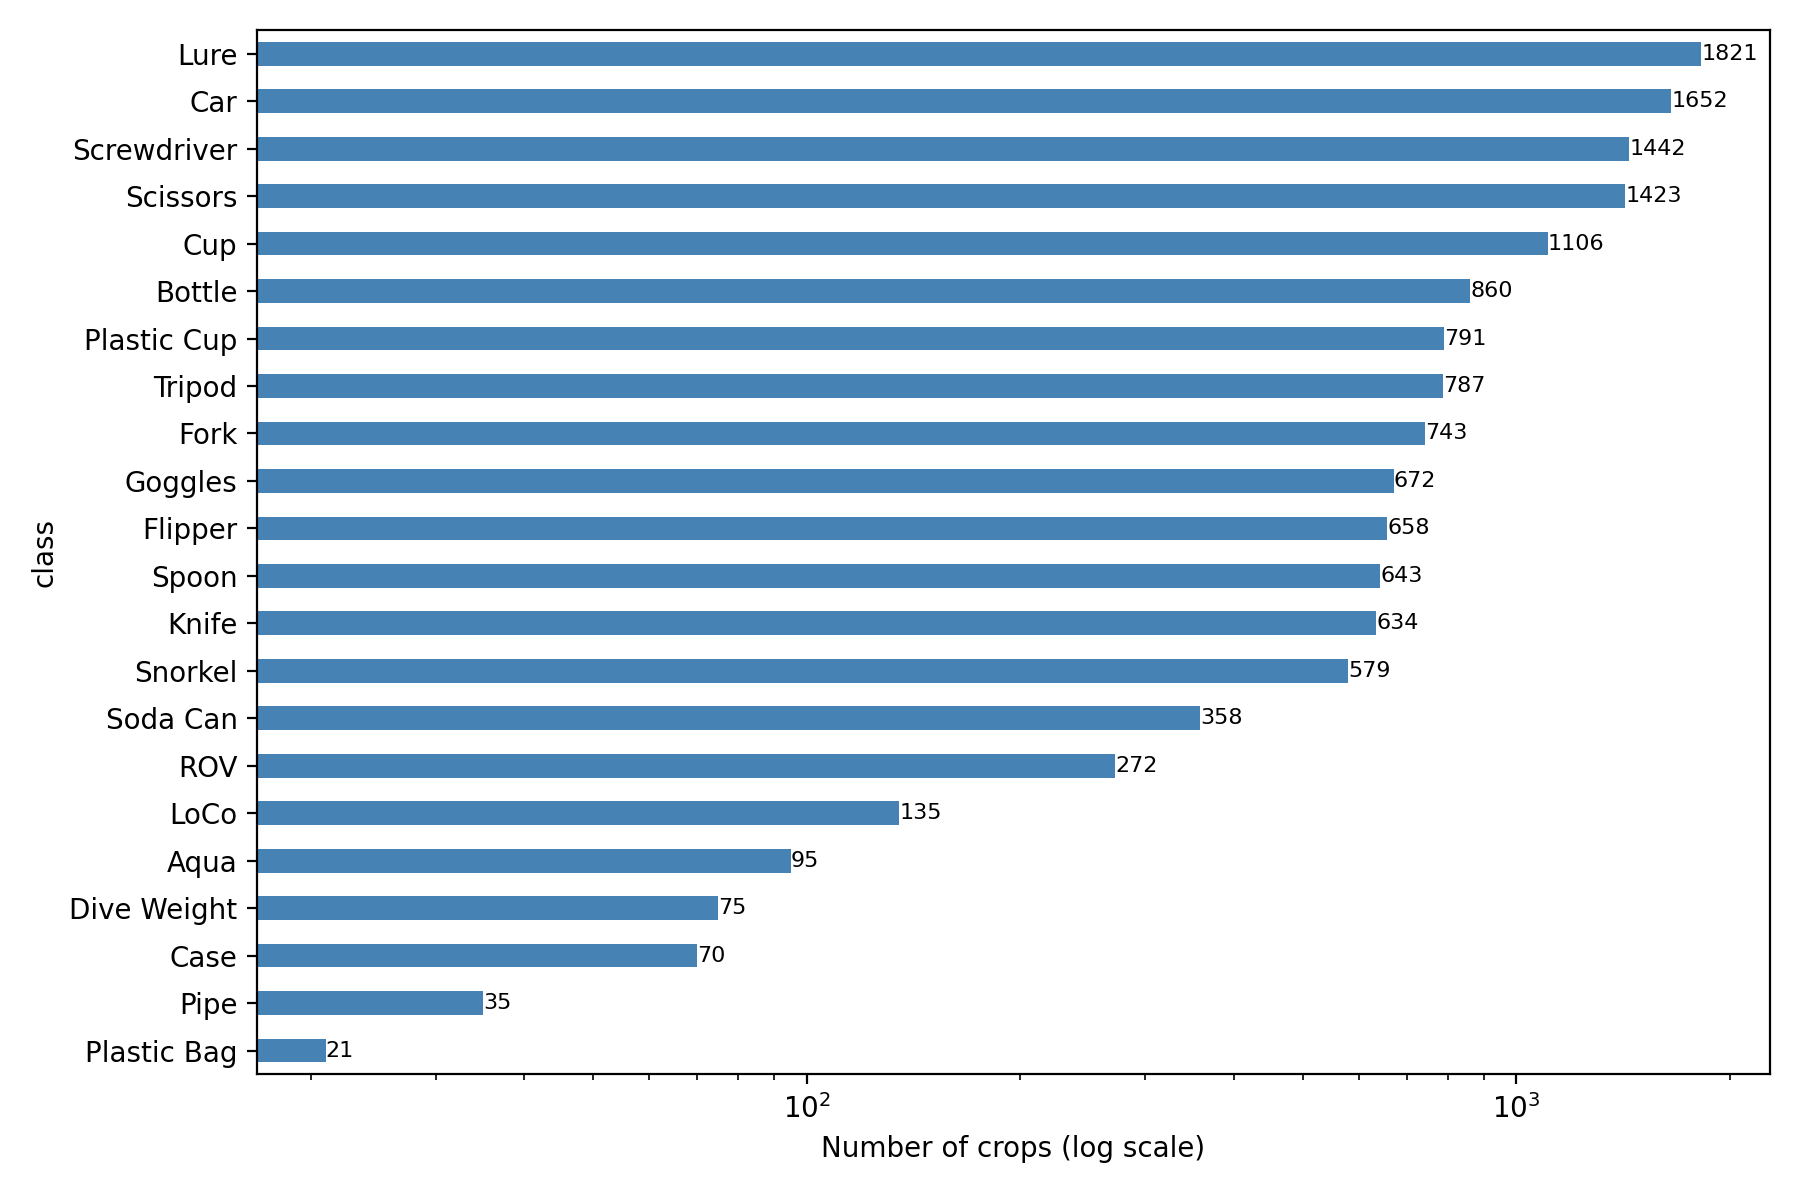

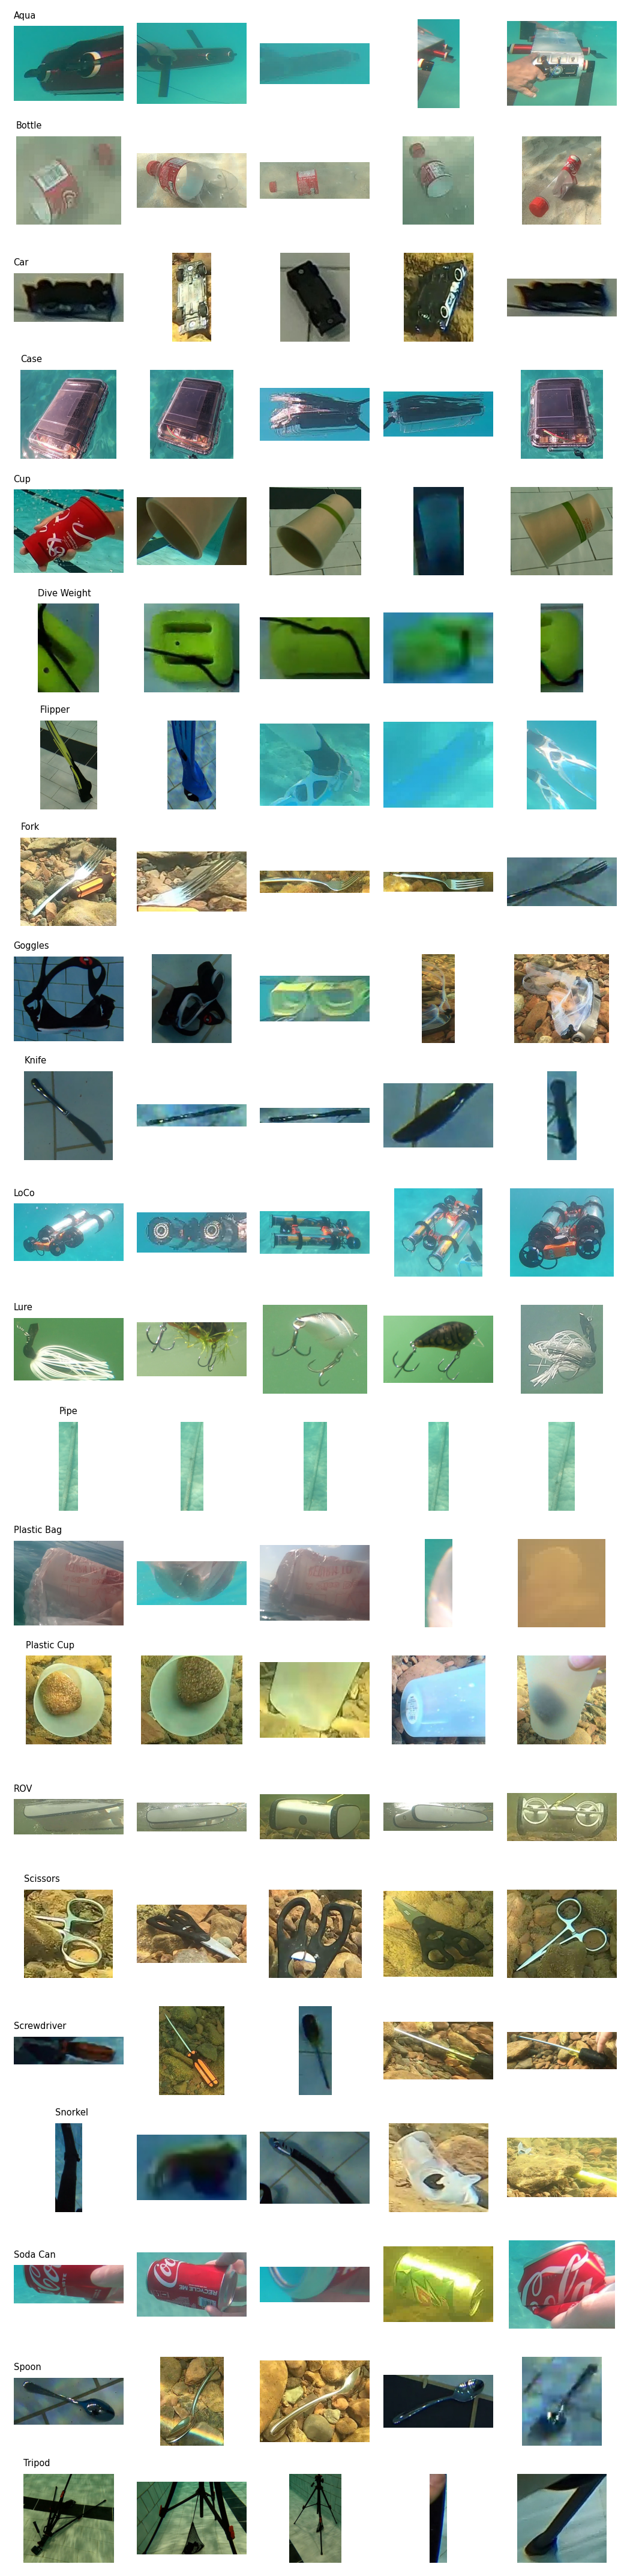

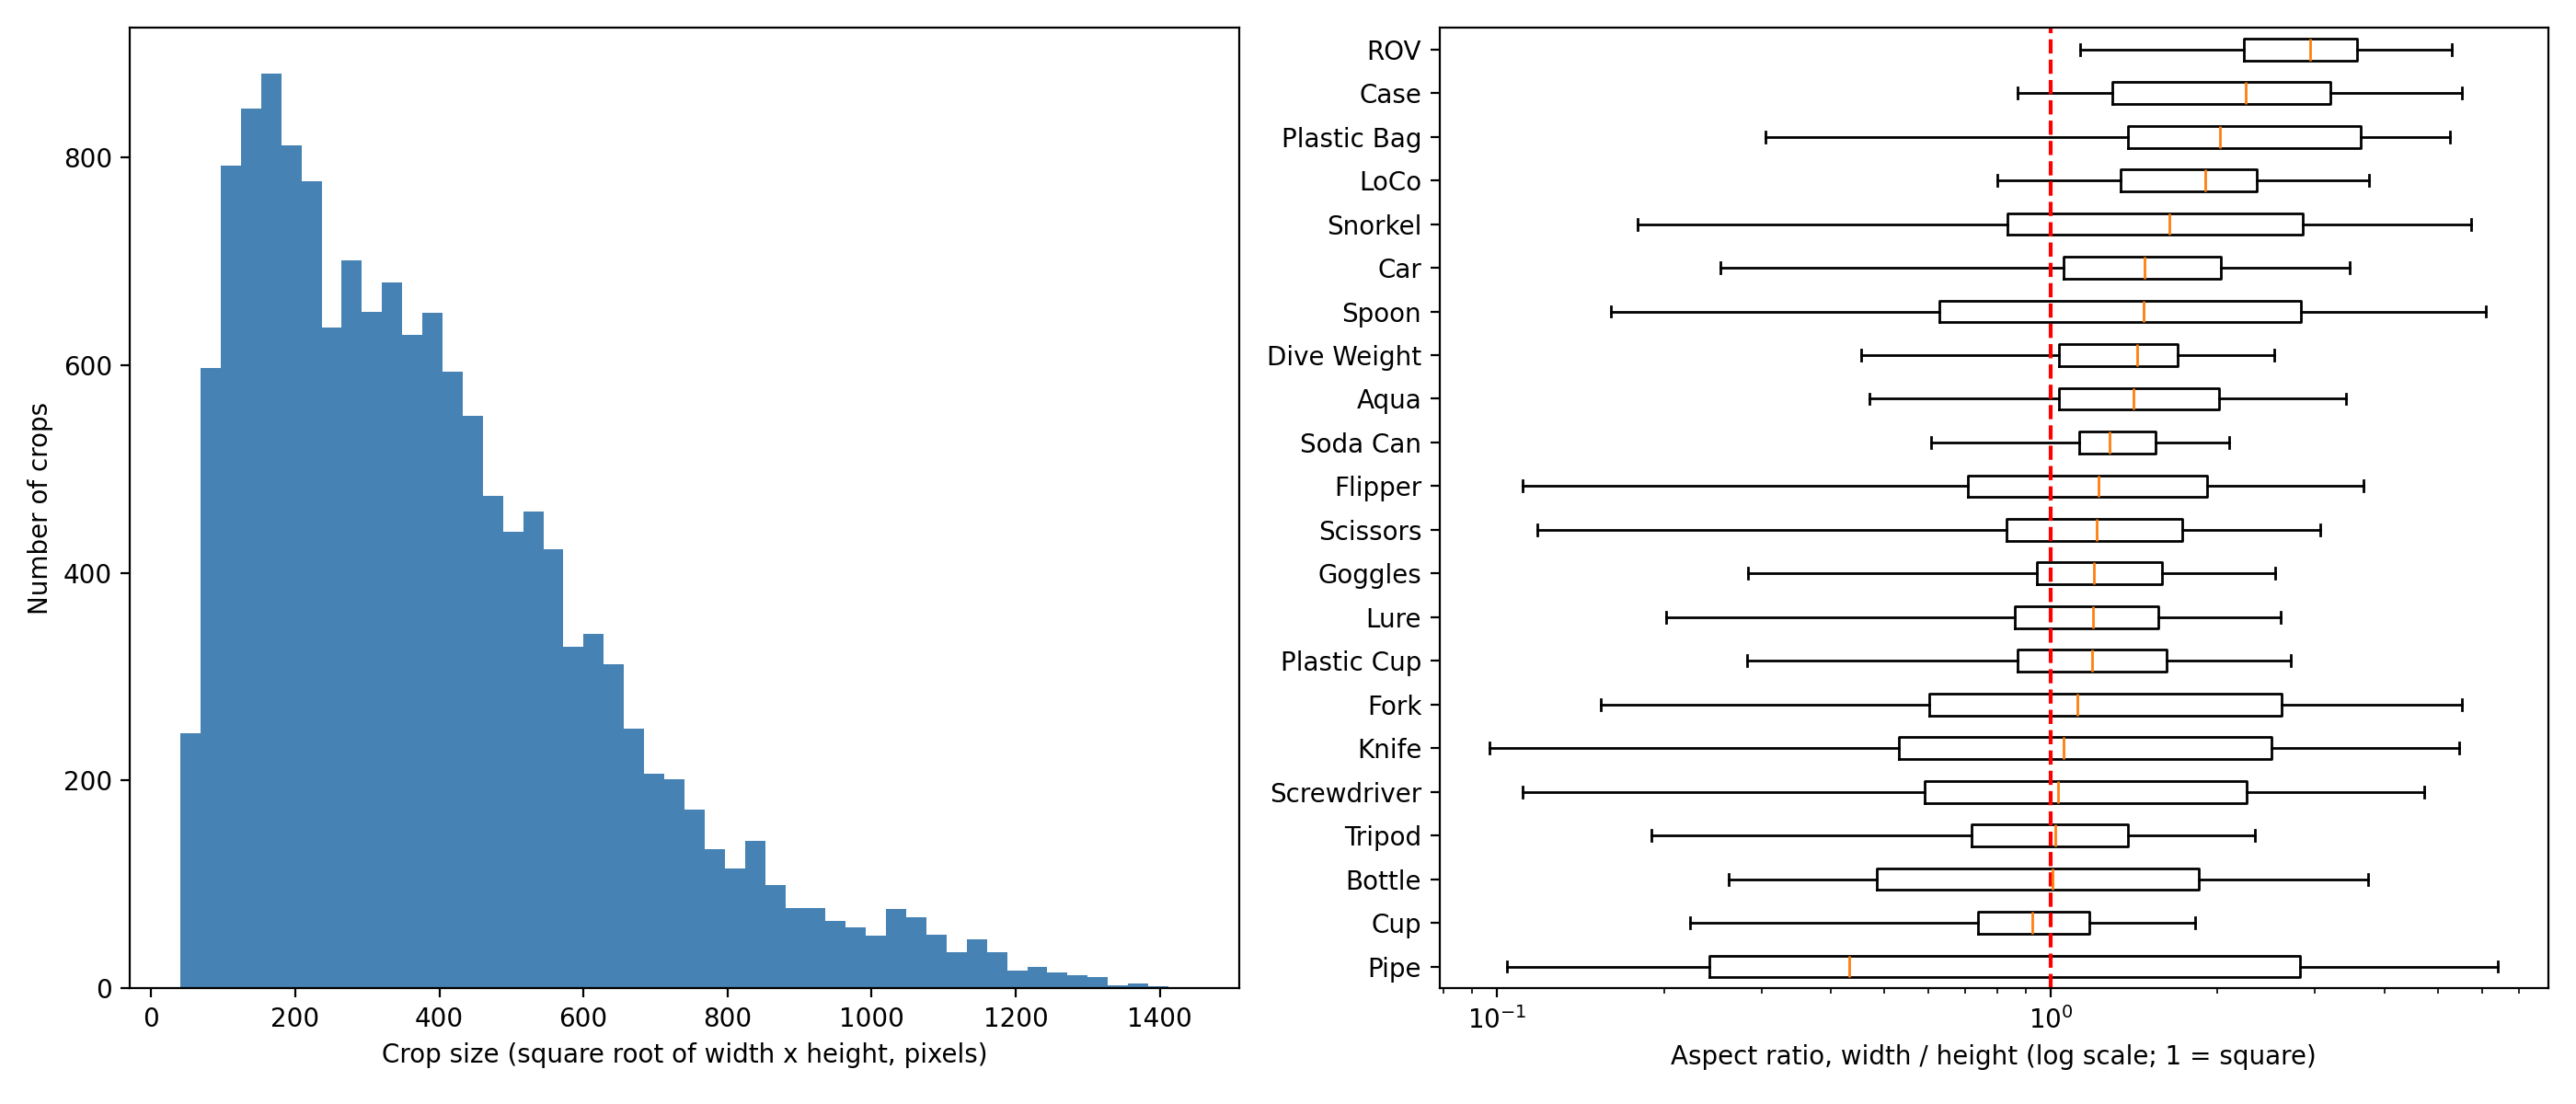

In [5]:
!python src/make_figures.py
!python src/crop_shapes.py
from IPython.display import Image, display
for f in ["class_counts", "sample_crops", "crop_shapes"]:
    display(Image(f"results/{f}.png", width=700))

## 5. CLIP models
Zero-shot CLIP also saves the frozen CLIP image features (`results/clip_img_feats.npy`) that the linear layer, the adapter, the ablation, the seed check and the NumPy classifier use.

In [6]:
!python src/clip_zeroshot.py
print(open("results/clip_zeroshot_report.txt").read()[:1500])


open_clip_model.safetensors: downloading bytes:  52% 315M/605M [00:02<00:01, 188MB/s, 27.2MB/s  ]
open_clip_model.safetensors: downloading bytes:  58% 349M/605M [00:02<00:01, 157MB/s, 29.4MB/s  ]
open_clip_model.safetensors: downloading bytes:  71% 427M/605M [00:03<00:00, 199MB/s, 34.4MB/s  ]
open_clip_model.safetensors: reconstructing file:  67% 402M/605M [00:03<00:01, 131MB/s, 30.8MB/s  ]
open_clip_model.safetensors: downloading bytes: 100% 432M/432M [00:04<00:00, 102MB/s, 37.1MB/s  ]
open_clip_model.safetensors: reconstructing file: 100% 605M/605M [00:04<00:00, 143MB/s, 52.6MB/s  ]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential

In [7]:
!python src/clip_linear.py
!python src/clip_adapter.py

==fold 0: accuracy 0.008 macro-f1 0.001
==fold 1: accuracy 0.878 macro-f1 0.807
==fold 2: accuracy 0.862 macro-f1 0.836

 Accuracy 0.582+-0.406

 Macro-F1 0.548+-0.387
              precision    recall  f1-score   support

        Aqua      0.018     0.937     0.035        95
      Bottle      0.957     0.567     0.712       860
         Car      0.922     0.623     0.744      1652
        Case      0.000     0.000     0.000        70
         Cup      0.874     0.619     0.725      1106
 Dive Weight      0.818     0.840     0.829        75
     Flipper      0.819     0.619     0.705       658
        Fork      0.740     0.471     0.576       743
     Goggles      0.833     0.518     0.639       672
       Knife      0.647     0.503     0.566       634
        LoCo      0.990     0.733     0.843       135
        Lure      0.994     0.746     0.852      1821
 Plastic Cup      0.958     0.603     0.740       791
         ROV      0.994     0.636     0.776       272
    Scissors      0.8

### Ablation, five-seed check and the from-scratch NumPy classifier

In [8]:
!python src/adapter_ablation.py
!python src/seeds_5.py
!python src/cosine_numpy.py

cosine classifier, random init     acc 0.594 +- 0.415 | F1 0.552 +- 0.389
cosine classifier, text init       acc 0.598 +- 0.417 | F1 0.556 +- 0.393
adapter + random init              acc 0.591 +- 0.413 | F1 0.547 +- 0.386
adapter + text init (full)         acc 0.598 +- 0.417 | F1 0.554 +- 0.391
linear   seed 0: accuracy 0.582  macro-F1 0.547
linear   seed 1: accuracy 0.583  macro-F1 0.548
linear   seed 2: accuracy 0.583  macro-F1 0.548
linear   seed 3: accuracy 0.582  macro-F1 0.548
linear   seed 4: accuracy 0.582  macro-F1 0.547
linear   over 5 seeds: accuracy 0.582 +- 0.000 | macro-F1 0.548 +- 0.000

adapter  seed 0: accuracy 0.598  macro-F1 0.552
adapter  seed 1: accuracy 0.598  macro-F1 0.555
adapter  seed 2: accuracy 0.598  macro-F1 0.572
adapter  seed 3: accuracy 0.597  macro-F1 0.553
adapter  seed 4: accuracy 0.596  macro-F1 0.555
adapter  over 5 seeds: accuracy 0.597 +- 0.001 | macro-F1 0.557 +- 0.007

Total time: 209 s
Gradient check: worst relative error 6.97e-08 (should be b

## 6. ResNet18 benchmarks (squashed and padded input)

In [11]:
!git -C /content/repo pull
!git -C /content/repo checkout -- data/manifest_folds.csv

remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4 (delta 1), reused 4 (delta 1), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 91.04 KiB | 3.37 MiB/s, done.
From https://github.com/urvidamani/underwater-object-clip
   9ecc4c2..86bcb12  main       -> origin/main
Updating 9ecc4c2..86bcb12
Fast-forward
 data/manifest_folds.csv | 14873 ++++++++++++++++++++++++++++++++++++++++++++++
 1 file changed, 14873 insertions(+)
 create mode 100644 data/manifest_folds.csv


In [12]:
if RUN_RESNET:
    !python src/train_resnet.py
    !python src/train_resnet_padded.py
else:
    print("Skipped. Set RUN_RESNET = True to train the ResNet18 models.")

20 classes:  ['Aqua', 'Bottle', 'Car', 'Case', 'Cup', 'Dive Weight', 'Flipper', 'Fork', 'Goggles', 'Knife', 'LoCo', 'Lure', 'Plastic Cup', 'ROV', 'Scissors', 'Screwdriver', 'Snorkel', 'Soda Can', 'Spoon', 'Tripod']
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker 

## 7. Statistical test and confusion matrices

resnet18 vs clip_adapter:only resnet18 right =4825,only clip_adapter right =759,p=0
clip_linear vs clip_adapter:only clip_linear right =281,only clip_adapter right =531,p=1.272e-18
resnet18 vs clip_linear:only resnet18 right =4987,only clip_linear right =671,p=0
resnet18_padded vs clip_adapter:only resnet18_padded right =4989,only clip_adapter right =348,p=0
resnet18_padded vs clip_linear:only resnet18_padded right =5213,only clip_linear right =322,p=0
resnet18 vs resnet18_padded:only resnet18 right =468,only resnet18_padded right =1043,p=1.484e-50
Car->Aqua:577
Screwdriver->Aqua:477
Lure->Aqua:453
Scissors->Aqua:420
Cup->Aqua:387
Tripod->Aqua:376
Bottle->Aqua:352
Plastic Cup->Aqua:303
Goggles->Aqua:251
Spoon->Aqua:240
Figure(1000x900)
Scissors->Goggles:109
Fork->Screwdriver:72
Snorkel->Goggles:66
Fork->Spoon:64
Screwdriver->Goggles:63
Spoon->Fork:52
Fork->Goggles:50
Knife->Spoon:49
Knife->Fork:49
Spoon->Scissors:46
Figure(1000x900)


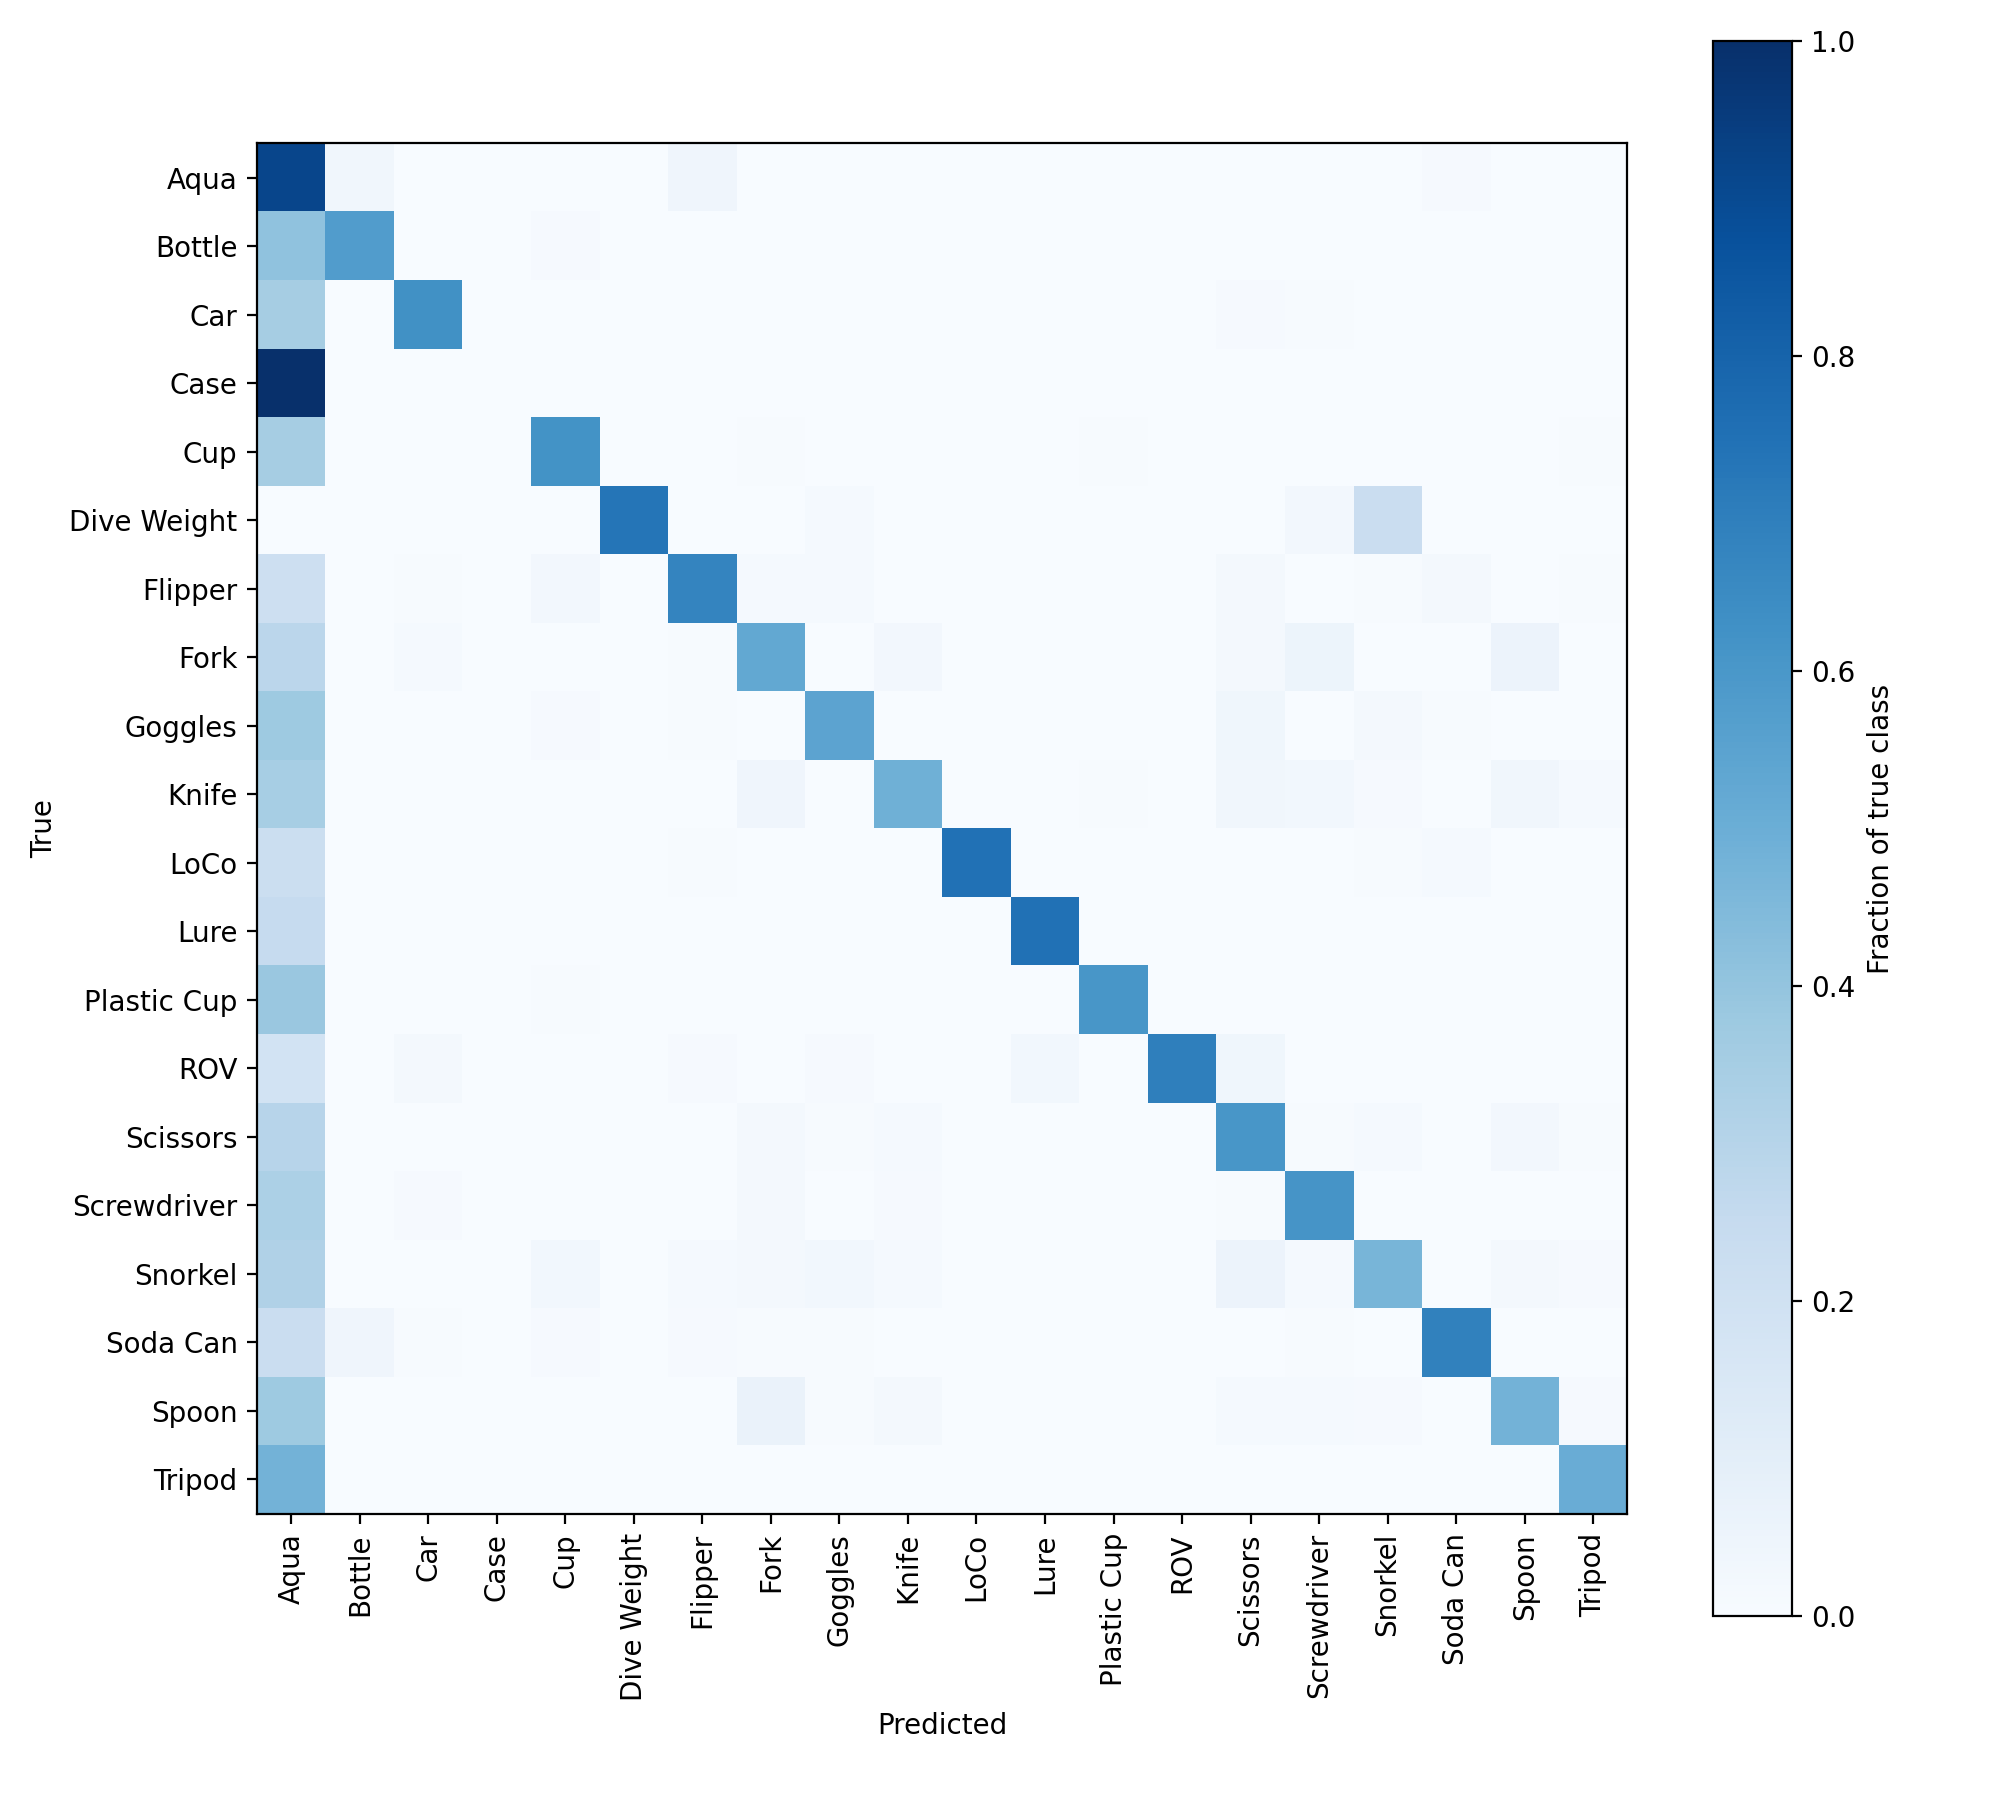

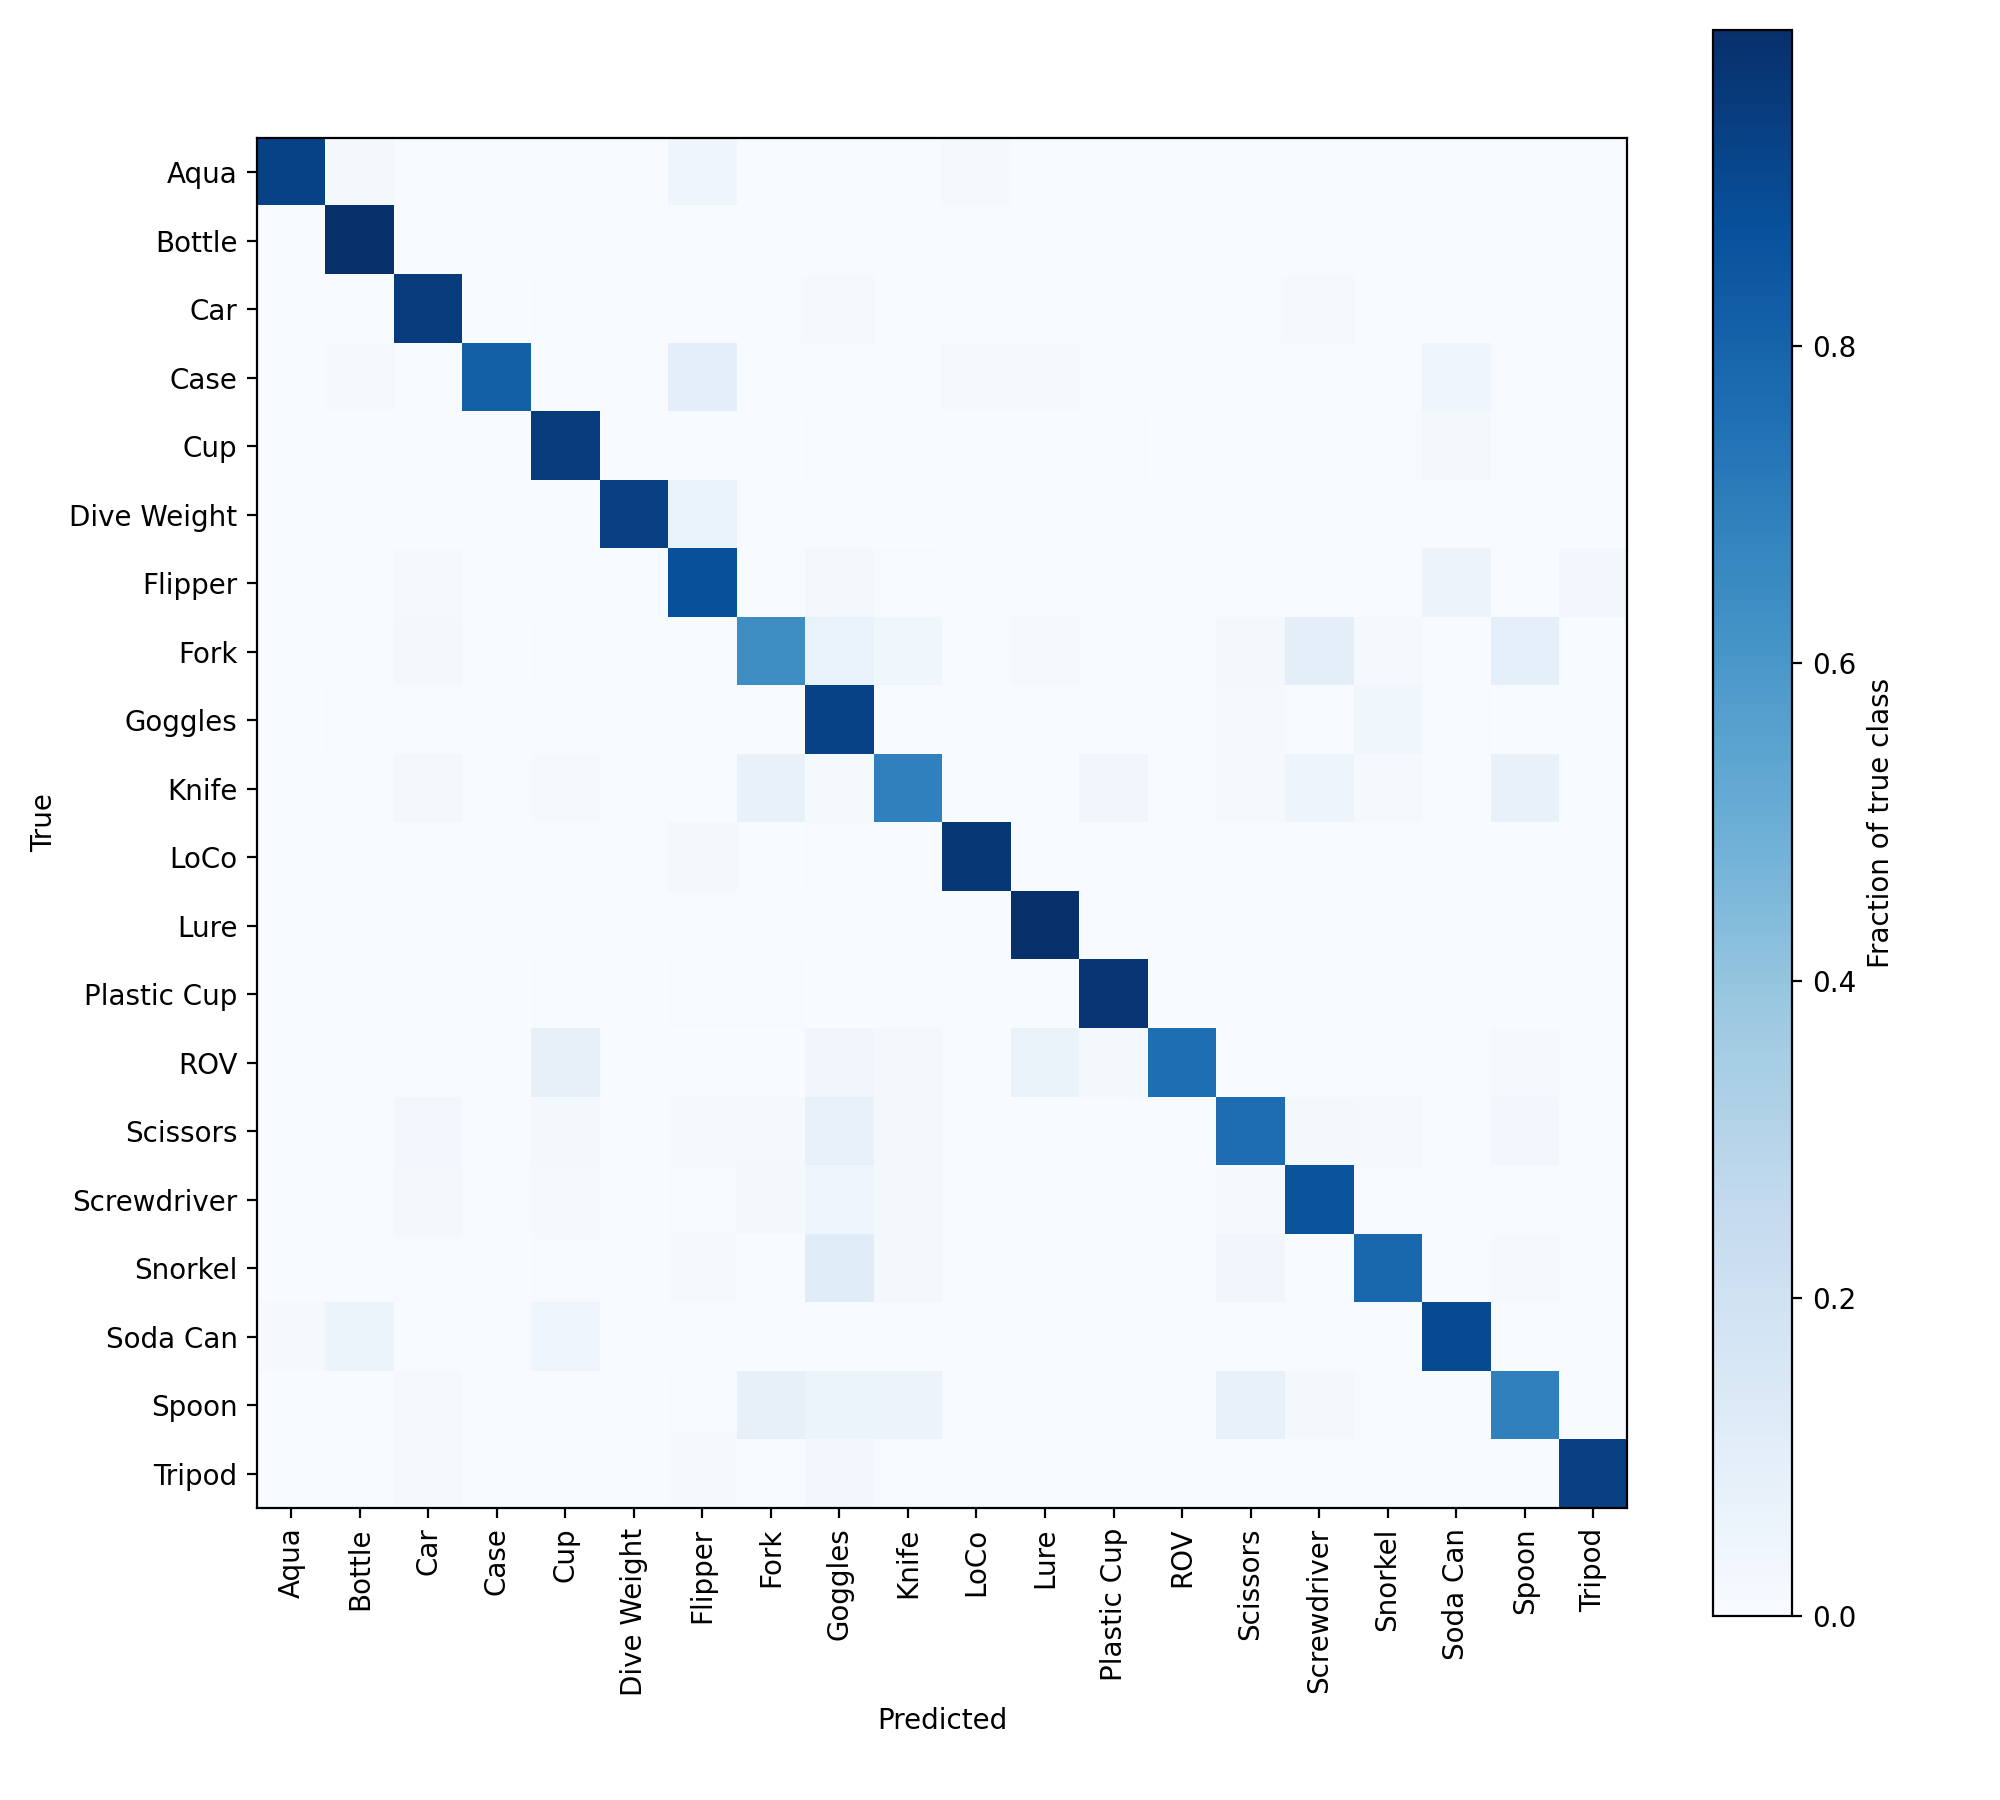

In [13]:
!python src/clip_significancetest.py
!python src/confusion.py clip_adapter
if RUN_RESNET:
    !python src/confusion.py resnet18
for f in ["clip_adapter_confusion", "resnet18_confusion"]:
    if os.path.exists(f"results/{f}.png"):
        display(Image(f"results/{f}.png", width=700))

## 8. Results summary
Mean and standard deviation over the three folds (20 classes).

In [14]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
rows = []
for name, label in [("resnet18", "ResNet18, squashed"), ("resnet18_padded", "ResNet18, padded"),
                    ("clip_linear", "CLIP + linear layer"), ("clip_adapter", "CLIP adapter"),
                    ("cosine_numpy", "Cosine classifier, NumPy")]:
    f = f"results/{name}_predictions.csv"
    if not os.path.exists(f):
        continue
    p = pd.read_csv(f)
    if "fold" in p.columns:
        s = np.array([(accuracy_score(g["class"], g["pred"]), f1_score(g["class"], g["pred"], average="macro"))
                      for _, g in p.groupby("fold")])
        rows.append([label, f"{s[:,0].mean():.3f} +- {s[:,0].std():.3f}", f"{s[:,1].mean():.3f} +- {s[:,1].std():.3f}"])
    else:
        rows.append([label, f"{accuracy_score(p['class'], p['pred']):.3f}",
                     f"{f1_score(p['class'], p['pred'], average='macro'):.3f}"])
display(pd.DataFrame(rows, columns=["Method", "Accuracy", "Macro-F1"]))

print("Five-seed check (mean over folds, then mean +- std over seeds):")
s5 = pd.read_csv("results/seeds_5.csv")
display(s5.groupby("model")[["acc", "f1"]].agg(["mean", "std"]).round(3))

,Method,Accuracy,Macro-F1
0,"ResNet18, squashed",0.879 +- 0.014,0.868 +- 0.024
1,"ResNet18, padded",0.918 +- 0.002,0.907 +- 0.004
2,CLIP + linear layer,0.582 +- 0.406,0.548 +- 0.387
3,CLIP adapter,0.599 +- 0.418,0.556 +- 0.393
4,"Cosine classifier, NumPy",0.597 +- 0.417,0.554 +- 0.391


Five-seed check (mean over folds, then mean +- std over seeds):


acc            f1       
          mean    std   mean    std
model                              
adapter  0.597  0.001  0.557  0.008
linear   0.582  0.000  0.548  0.000

## 9. Notes
- The full report discusses these results, the benchmark differences, the padding decision (made after seeing test results) and the limitations.
- Numbers can differ in the last digit from the report because GPU training is not perfectly deterministic and the Colab GPU differs from the laptop GPU used for the report.
- `src/complexity.py`, `src/time_features.py` and `src/time_linear.py` give the parameter counts and timings in the report. Timings from Colab will differ from the report, which used an RTX 4050 laptop GPU.